# HPKM: Recursive Hyperplane Partitioning based centroid initialisation for k-means

This notebook reproduces **all** the results of the revised manuscript and of its Supplementary Material in one run:

* **Table 3** of the manuscript: KM, k-means++, ECKM and HPKM on the 11 datasets, with the improvement of HPKM over each baseline.
* **Cumulative explained variance** of the first two principal components (Section 3.2).
* **Convergence analysis** (Fig. 3): number of iterations over 100 runs on D31.
* **Per-dataset figures** (clustering plots and metric bar charts).
* **Supplementary Tables S1 to S3**: comparison with Var-Part, and the variability of KM and k-means++ over 30 seeds.

**Experimental protocol (same for every method)**

* The class label column is used only for evaluation. It is **excluded** before PCA and before clustering.
* PCA to two components is applied only to datasets with more than two feature columns (Hepta, Iris, Breast, Yeast, Wine).
* All methods (KM, k-means++, ECKM, Var-Part, HPKM) refine their initial centroids with the **same** k-means routine (`kmeans_iterative`, at most 100 iterations, tolerance $10^{-4}$), so the iteration counts are directly comparable.
* HPKM splits, in each step, the partition with the **largest number of points**, along the axis with the larger range (spread), at the midpoint of that range.
* Execution time is **end-to-end** (initialisation + k-means iterations), measured with `time.perf_counter`. Plotting and metric computation are outside the timed region. For deterministic runs the median of `TIME_REPEATS` repetitions is reported.
* Random seeds: KM and k-means++ use seed `SEED = 42` in Table 3; seeds `0..29` are used for the variability study and `0..99` for the convergence analysis. ECKM, Var-Part and HPKM are deterministic.

**How to run:** put the 11 CSV files in the folder `Datasets/` (each file has the feature columns and a column named `Class`), then run all cells. All outputs are written to `Results/`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import time, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from decimal import Decimal, ROUND_HALF_UP
from scipy.spatial.distance import cdist
from scipy.spatial import Voronoi, ConvexHull
from shapely.geometry import Point, Polygon
from sklearn.decomposition import PCA
from sklearn.cluster import kmeans_plusplus
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             homogeneity_score, completeness_score, v_measure_score)
warnings.filterwarnings("ignore")

# ------------------------------- settings -------------------------------
DATA_DIR  = "Datasets/"
OUT_DIR   = "Results/"
DATASETS  = ["S1", "Aggregation", "D31", "Flame", "Hepta", "R15", "Target",   # synthetic
             "Iris", "Breast", "Yeast", "Wine"]                               # real
SYNTHETIC = DATASETS[:7]
REAL      = DATASETS[7:]
CLASS_COL    = "Class"
SEED         = 42          # seed of KM and k-means++ in Table 3
N_RUNS       = 30          # runs of KM and k-means++ for the variability study
CONV_RUNS    = 100         # runs for the convergence analysis (Fig. 3)
CONV_DATASET = "D31"
TIME_REPEATS = 5           # repetitions for timing deterministic runs (median)
MAX_ITER, TOL = 100, 1e-4
FIG_DATASETS = ["S1", "Aggregation", "D31", "Hepta", "R15"]   # datasets with figures in the paper

for sub in ["", "Plots", "Metrics_plots", "Iterations", "Tables"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
import sklearn, scipy, platform
print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | scikit-learn 1.9.1 | pandas 3.0.5


## 1. Data loading and PCA (class label excluded)

In [2]:
def read_points_csv(path, class_col=CLASS_COL):
    # Returns the 2-D data X, the true labels y and PCA information.
    # The class column is removed BEFORE PCA, so no label information enters the features.
    df = pd.read_csv(path)
    y = pd.factorize(df[class_col])[0]                      # labels are used only for evaluation
    feats = df.drop(columns=[class_col]).select_dtypes(include="number")
    info = {"n_features": feats.shape[1], "pca": False, "ev1": np.nan, "ev2": np.nan, "cum_ev": np.nan}
    if feats.shape[1] > 2:
        pca = PCA(n_components=2)
        X = pca.fit_transform(feats.values)
        ev = pca.explained_variance_ratio_
        info.update(pca=True, ev1=ev[0], ev2=ev[1], cum_ev=ev.sum())
    else:
        X = feats.values.astype(float)
    return np.ascontiguousarray(X, dtype=float), y, info

DATA = {}
for name in DATASETS:
    X, y, info = read_points_csv(os.path.join(DATA_DIR, name + ".csv"))
    DATA[name] = (X, y, len(np.unique(y)), info)

ev_table = pd.DataFrame([{"Dataset": n, "Points": len(DATA[n][0]), "k": DATA[n][2],
                          "Features": DATA[n][3]["n_features"], "PCA applied": DATA[n][3]["pca"],
                          "PC1 (%)": 100*DATA[n][3]["ev1"], "PC2 (%)": 100*DATA[n][3]["ev2"],
                          "Cumulative (%)": 100*DATA[n][3]["cum_ev"]} for n in DATASETS])
ev_table.to_csv(OUT_DIR + "Tables/explained_variance.csv", index=False)
ev_table.round(1)

,Dataset,Points,k,Features,PCA applied,PC1 (%),PC2 (%),Cumulative (%)
0,S1,5000,15,2,False,NaN,NaN,NaN
1,Aggregation,788,7,2,False,NaN,NaN,NaN
2,D31,3100,31,2,False,NaN,NaN,NaN
3,Flame,240,2,2,False,NaN,NaN,NaN
4,Hepta,212,7,3,True,34.7,33.7,68.5
5,R15,600,15,2,False,NaN,NaN,NaN
6,Target,770,6,2,False,NaN,NaN,NaN
7,Iris,150,3,4,True,92.5,5.3,97.8
8,Breast,699,9,8,True,70.9,7.5,78.4
9,Yeast,1484,10,8,True,35.3,21.3,56.6


## 2. Initialisation methods

* **KM**: $k$ data points chosen at random.
* **k-means++**: scikit-learn implementation of the $D^2$ seeding (Arthur and Vassilvitskii, 2007).
* **ECKM**: initial centres taken from the boundary points of the largest empty circles (Voronoi vertices inside the convex hull), as in Biswas et al. (2023).
* **Var-Part** (Su and Dy, 2007): split the cell with the largest SSE along its dimension of largest variance, at the mean.
* **HPKM** (proposed): split the partition with the largest number of points along the axis with the larger range, at the midpoint; the mean of each final partition is an initial centroid.

In [3]:
def km_random_init(X, k, seed):
    return X[np.random.RandomState(seed).choice(len(X), k, replace=False)].copy()

def kmeanspp_init(X, k, seed):
    centers, _ = kmeans_plusplus(X, n_clusters=k, random_state=seed)
    return centers

def eckm_init(X, k, tol=1e-6):
    hull = ConvexHull(X)
    vor = Voronoi(X)
    polygon = Polygon(hull.points[hull.vertices])
    inner = np.array([v for v in vor.vertices if polygon.contains(Point(v))])
    radii = cdist(inner, X).min(axis=1)                        # largest empty circles
    order = np.argsort(-radii, kind="stable")
    seen = {}
    for idx in order:
        d = cdist(inner[idx:idx+1], X)[0]
        for pt in X[np.abs(d - radii[idx]) < tol]:
            seen.setdefault(tuple(pt), None)
        if len(seen) >= k:
            break
    return np.array(list(seen.keys()))[:k]

def varpart_init(X, k):
    cells = [np.arange(len(X))]
    while len(cells) < k:
        sse = [((X[c] - X[c].mean(axis=0)) ** 2).sum() for c in cells]
        c = cells.pop(int(np.argmax(sse)))
        P = X[c]; d = int(np.argmax(P.var(axis=0))); m = P[:, d].mean()
        left, right = c[P[:, d] <= m], c[P[:, d] > m]
        if len(left) == 0 or len(right) == 0:
            cells.append(c); break
        cells += [left, right]
    return np.array([X[c].mean(axis=0) for c in cells])

def hpkm_partition(X, k):
    # Recursive hyperplane partitioning of HPKM. Returns the list of index arrays of the k partitions.
    regions = [np.arange(len(X))]
    while len(regions) < k:
        regions.sort(key=len, reverse=True)                    # partition with the largest number of points
        largest = regions.pop(0)
        if len(largest) <= 1:
            regions.append(largest); break
        P = X[largest]
        axis = 0 if np.ptp(P[:, 0]) > np.ptp(P[:, 1]) else 1  # axis with the larger spread (range)
        mid = (P[:, axis].max() + P[:, axis].min()) / 2       # perpendicular bisector at the midpoint
        p1, p2 = largest[P[:, axis] <= mid], largest[P[:, axis] > mid]
        if len(p1) == 0 or len(p2) == 0:
            regions.append(largest); break
        regions.extend([p1, p2])
    return regions

def hpkm_init(X, k):
    return np.array([X[r].mean(axis=0) for r in hpkm_partition(X, k)])

## 3. Common k-means routine, metrics and timing

In [4]:
def kmeans_iterative(X, k, init, max_iter=MAX_ITER, tol=TOL):
    centroids = init.copy()
    for p in range(max_iter):
        labels = np.argmin(cdist(X, centroids), axis=1)
        new = np.array([X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i] for i in range(k)])
        if np.linalg.norm(new - centroids) < tol:
            break
        centroids = new
    return labels, centroids, p          # p = iteration count reported in the paper

def evaluate(X, y, labels, centroids):
    return {"SH": silhouette_score(X, labels), "DBI": davies_bouldin_score(X, labels),
            "ARI": adjusted_rand_score(y, labels), "HM": homogeneity_score(y, labels),
            "CM": completeness_score(y, labels), "VM": v_measure_score(y, labels),
            "ED": np.mean(np.min(cdist(X, centroids), axis=1))}

INIT = {"KM":        lambda X, k, s: km_random_init(X, k, s),
        "K-Means++": lambda X, k, s: kmeanspp_init(X, k, s),
        "ECKM":      lambda X, k, s: eckm_init(X, k),
        "Var-Part":  lambda X, k, s: varpart_init(X, k),
        "HPKM":      lambda X, k, s: hpkm_init(X, k)}

def run(method, X, y, k, seed=SEED, repeats=1):
    # End-to-end run: initialisation + k-means. Returns metrics, time (s) and iterations.
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        init = INIT[method](X, k, seed)
        labels, cents, it = kmeans_iterative(X, k, init)
        times.append(time.perf_counter() - t0)
    res = evaluate(X, y, labels, cents)
    res.update({"Time (s)": float(np.median(times)), "Iteration": int(it)})
    return res, labels, cents, init

## 4. Table 3 of the manuscript (KM, k-means++, ECKM, HPKM)

In [5]:
METHODS_T3 = ["KM", "K-Means++", "HPKM", "ECKM"]
MET  = ["SH", "DBI", "ARI", "HM", "CM", "VM", "ED", "Time (s)", "Iteration"]
HIGH = {"SH": True, "DBI": False, "ARI": True, "HM": True, "CM": True, "VM": True,
        "ED": False, "Time (s)": False, "Iteration": False}

rows, RUNS = [], {}
for name in DATASETS:
    X, y, k, _ = DATA[name]
    for m in METHODS_T3:
        res, labels, cents, init = run(m, X, y, k, SEED, repeats=TIME_REPEATS)
        RUNS[(name, m)] = (labels, cents, init)
        rows.append({"Dataset": name, "Method": m, **res})
T3 = pd.DataFrame(rows).set_index(["Dataset", "Method"])

def improvement(h, b, high):
    if b == 0: return np.nan
    return 100 * ((h - b) / abs(b) if high else (b - h) / abs(b))

imp_rows = []
for name in DATASETS:
    for base in ["KM", "K-Means++", "ECKM"]:
        imp_rows.append({"Dataset": name, "Baseline": base,
                         **{c: improvement(T3.loc[(name, "HPKM"), c], T3.loc[(name, base), c], HIGH[c]) for c in MET}})
IMP = pd.DataFrame(imp_rows).set_index(["Dataset", "Baseline"])

with pd.ExcelWriter(OUT_DIR + "Tables/Table3_results.xlsx") as xw:
    T3.to_excel(xw, sheet_name="Results")
    IMP.to_excel(xw, sheet_name="Improvement (%)")
    ev_table.to_excel(xw, sheet_name="Explained variance", index=False)
T3.round(4)

SH     DBI     ARI      HM      CM      VM  \
Dataset     Method                                                      
S1          KM         0.6512  0.5228  0.8976  0.9506  0.9683  0.9594   
            K-Means++  0.7113  0.3664  0.9864  0.9863  0.9863  0.9863   
            HPKM       0.7113  0.3664  0.9864  0.9863  0.9863  0.9863   
            ECKM       0.6137  0.5881  0.8328  0.9122  0.9510  0.9312   
Aggregation KM         0.4606  0.8238  0.6424  0.8459  0.7588  0.8000   
            K-Means++  0.4831  0.6993  0.7387  0.8825  0.8008  0.8397   
            HPKM       0.4809  0.7332  0.7600  0.9265  0.8321  0.8768   
            ECKM       0.4778  0.7270  0.7453  0.8830  0.8182  0.8494   
D31         KM         0.4962  0.7132  0.7415  0.8846  0.9150  0.8996   
            K-Means++  0.5335  0.6494  0.8686  0.9374  0.9469  0.9421   
            HPKM       0.5755  0.5472  0.9535  0.9676  0.9676  0.9676   
            ECKM       0.4817  0.7343  0.7304  0.8774  0.9191  0.8978   
Flame       KM         0.3785  1.1154  0.4534  0.4101  0.3881  0.3988   
            K-Means++  0.3706  1.1178  0.4649  0.4391  0.4150  0.4267   
            HPKM       0.3775  1.1213  0.4312  0.4054  0.3831  0.3939   
            ECKM       0.3785  1.1154  0.4534  0.4101  0.3881  0.3988   
Hepta       KM         0.6307  0.5171  0.9466  0.9588  0.9611  0.9600   
            K-Means++  0.6307  0.5207  0.9552  0.9598  0.9610  0.9604   
            HPKM       0.6304  0.5226  0.9568  0.9696  0.9714  0.9705   
            ECKM       0.5356  0.7017  0.7834  0.8770  0.9221  0.8990   
R15         KM         0.6509  0.6109  0.9044  0.9566  0.9739  0.9651   
            K-Means++  0.7527  0.3148  0.9928  0.9942  0.9942  0.9942   
            HPKM       0.6711  0.5149  0.9037  0.9548  0.9709  0.9628   
            ECKM       0.5392  0.7714  0.7069  0.8585  0.9117  0.8843   
Target      KM         0.5779  0.6390  0.6364  0.9155  0.4884  0.6370   
            K-Means++  0.5815  0.6134  0.6352  0.9162  0.4874  0.6363   
            HPKM       0.5626  0.6721  0.6351  0.9153  0.4873  0.6360   
            ECKM       0.4772  0.6251  0.4371  0.5878  0.4140  0.4859   
Iris        KM         0.5976  0.5651  0.7163  0.7364  0.7475  0.7419   
            K-Means++  0.5976  0.5651  0.7163  0.7364  0.7475  0.7419   
            HPKM       0.5976  0.5651  0.7163  0.7364  0.7475  0.7419   
            ECKM       0.5976  0.5651  0.7163  0.7364  0.7475  0.7419   
Breast      KM         0.4139  0.8026  0.0637  0.2405  0.0929  0.1340   
            K-Means++  0.4697  0.8755  0.1904  0.2589  0.1161  0.1603   
            HPKM       0.4190  0.7233  0.1037  0.2557  0.1025  0.1463   
            ECKM       0.6420  0.8066  0.3437  0.2550  0.1417  0.1821   
Yeast       KM         0.3505  0.8930  0.0799  0.2047  0.1645  0.1824   
            K-Means++  0.3572  0.8318  0.0709  0.1989  0.1588  0.1766   
            HPKM       0.3570  0.8372  0.0722  0.2031  0.1617  0.1800   
            ECKM       0.3513  0.7901  0.0814  0.1944  0.1701  0.1814   
Wine        KM         0.5723  0.5330  0.3711  0.4288  0.4287  0.4288   
            K-Means++  0.5603  0.5487  0.3518  0.3988  0.4510  0.4233   
            HPKM       0.5723  0.5330  0.3711  0.4288  0.4287  0.4288   
            ECKM       0.5603  0.5487  0.3518  0.3988  0.4510  0.4233   

                               ED  Time (s)  Iteration  
Dataset     Method                                      
S1          KM         42189.2462    0.0175         20  
            K-Means++  33877.5741    0.0061          3  
            HPKM       33877.5741    0.0056          3  
            ECKM       49799.4716    0.2636         23  
Aggregation KM             3.7425    0.0015         10  
            K-Means++      3.5126    0.0022         10  
            HPKM           3.4435    0.0010          6  
            ECKM           3.5447    0.0138          8  
D31         KM             1.1759    0.0138         12  
            K-Means++      1.0225    0.01

In [6]:
IMP.round(2)

SH    DBI    ARI     HM     CM     VM     ED  \
Dataset     Baseline                                                     
S1          KM          9.23  29.91   9.89   3.76   1.86   2.81  19.70   
            K-Means++   0.00  -0.00   0.00   0.00   0.00   0.00   0.00   
            ECKM       15.91  37.69  18.45   8.12   3.71   5.92  31.97   
Aggregation KM          4.40  11.00  18.31   9.53   9.65   9.59   7.99   
            K-Means++  -0.45  -4.85   2.89   4.99   3.90   4.42   1.97   
            ECKM        0.65  -0.85   1.97   4.93   1.69   3.22   2.86   
D31         KM         15.99  23.28  28.60   9.38   5.75   7.56  20.84   
            K-Means++   7.88  15.74   9.78   3.23   2.19   2.71   8.95   
            ECKM       19.48  25.48  30.56  10.28   5.28   7.78  23.85   
Flame       KM         -0.26  -0.53  -4.90  -1.15  -1.30  -1.23  -0.25   
            K-Means++   1.88  -0.32  -7.24  -7.68  -7.70  -7.69  -2.01   
            ECKM       -0.26  -0.53  -4.90  -1.15  -1.30  -1.23  -0.25   
Hepta       KM         -0.05  -1.06   1.08   1.12   1.07   1.10  -0.19   
            K-Means++  -0.05  -0.36   0.16   1.01   1.08   1.04  -1.26   
            ECKM       17.70  25.52  22.13  10.55   5.34   7.95  22.08   
R15         KM          3.10  15.71  -0.08  -0.19  -0.30  -0.24  36.94   
            K-Means++ -10.85 -63.57  -8.98  -3.97  -2.35  -3.16 -18.04   
            ECKM       24.47  33.25  27.83  11.22   6.49   8.87  23.26   
Target      KM         -2.64  -5.18  -0.21  -0.03  -0.23  -0.16  -2.11   
            K-Means++  -3.23  -9.58  -0.02  -0.10  -0.03  -0.05  -4.18   
            ECKM       17.91  -7.52  45.29  55.70  17.69  30.90  24.41   
Iris        KM          0.00   0.00   0.00   0.00   0.00   0.00   0.00   
            K-Means++   0.00   0.00   0.00   0.00   0.00   0.00   0.00   
            ECKM        0.00   0.00   0.00   0.00   0.00   0.00   0.00   
Breast      KM          1.22   9.88  62.84   6.30  10.35   9.19   6.36   
            K-Means++ -10.79  17.38 -45.55  -1.25 -11.71  -8.72   2.92   
            ECKM      -34.73  10.32 -69.83   0.25 -27.65 -19.67  12.90   
Yeast       KM          1.85   6.25  -9.63  -0.79  -1.72  -1.31   0.30   
            K-Means++  -0.06  -0.65   1.93   2.09   1.83   1.95  -0.41   
            ECKM        1.62  -5.96 -11.29   4.48  -4.97  -0.78   8.51   
Wine        KM          0.00   0.00   0.00  -0.00  -0.00  -0.00   0.00   
            K-Means++   2.14   2.87   5.50   7.53  -4.95   1.29  10.21   
            ECKM        2.14   2.87   5.50   7.53  -4.95   1.29  10.21   

                       Time (s)  Iteration  
Dataset     Baseline                        
S1          KM            67.91      85.00  
            K-Means++      8.43       0.00  
            ECKM          97.86      86.96  
Aggregation KM            30.90      40.00  
            K-Means++     52.37      40.00  
            ECKM          92.57      25.00  
D31         KM            25.84      33.33  
            K-Means++     28.44       0.00  
            ECKM          93.56      65.22  
Flame       KM           -12.19     -66.67  
            K-Means++     33.54    -233.33  
            ECKM          88.62      16.67  
Hepta       KM            51.99      40.00  
            K-Means++     74.85       0.00  
            ECKM          88.74      62.50  
R15         KM            14.87      28.57  
            K-Means++     45.87      16.67  
            ECKM          83.38      50.00  
Target      KM           -10.18     -11.11  
            K-Means++     43.20       0.00  
            ECKM          89.62      23.08  
Iris        KM            20.66      16.67  
            K-Means++     64.85      44.44  
            ECKM          86.27       0.00  
Breast      KM           -97.61    -106.67  
            K-Means++    -80.50    -244.44  
            ECKM          46.45    -244.44  
Yeast       KM           -95.73     -50.00  
            K-Means++     21.99      26.83  
            ECKM          74.70     -25.

### LaTeX of Table 3 (HPKM wins in bold)

In [7]:
def q(x, p="0.01"):
    return Decimal(repr(float(x))).quantize(Decimal(p), rounding=ROUND_HALF_UP)

def shown(v, c):
    return Decimal(int(round(v))) if c == "Iteration" else q(v)

def fmt(v, c):
    return f"{int(round(v))}" if c == "Iteration" else f"{q(v)}"

def fmt_imp(v):
    if np.isnan(v): return "--"
    s = q(v)
    if s == 0: return "0.00"
    return f"\\textbf{{+{s}}}" if s > 0 else f"$-${abs(s)}"

def latex_block(name):
    out = []
    for i, m in enumerate(METHODS_T3):
        cells = []
        for c in MET:
            t = fmt(T3.loc[(name, m), c], c)
            if m == "HPKM":
                h = shown(T3.loc[(name, m), c], c)
                others = [shown(T3.loc[(name, o), c], c) for o in METHODS_T3 if o != "HPKM"]
                if (h > max(others)) if HIGH[c] else (h < min(others)):
                    t = f"\\textbf{{{t}}}"
            cells.append(t)
        label = "\\textbf{HPKM}" if m == "HPKM" else m
        out.append(f"{name if i == 0 else ''} & {label} & " + " & ".join(cells) + r" \\")
    for base in ["KM", "K-Means++", "ECKM"]:
        out.append(f"& Imp.\\ over {base} (\\%) & " + " & ".join(fmt_imp(IMP.loc[(name, base), c]) for c in MET) + r" \\")
    return "\n".join(out)

caption = (r"Multi-parameter analysis of KM, K-Means++, ECKM and HPKM on the synthetic and real datasets. "
           r"Improvement (\%) is $(\mathrm{HPKM}-\mathrm{baseline})/|\mathrm{baseline}|$ for SH, ARI, HM, CM and VM, and "
           r"$(\mathrm{baseline}-\mathrm{HPKM})/|\mathrm{baseline}|$ for DBI, ED, time and iterations, so a positive value always means that HPKM is better. "
           r"Bold values mark where HPKM wins: in the method rows, HPKM is better than all the other methods; in the improvement rows, HPKM is better than that baseline. "
           r"Time is the end-to-end time (initialisation and k-means iterations), and KM and K-Means++ use the random seed 42.")
lines = [r"\begin{table*}[p]", r"\color{blue}", r"\centering", f"\\caption{{{caption}}}", r"\label{tab:parameter_analysis}",
         r"\scriptsize", r"\setlength{\tabcolsep}{3pt}", r"\renewcommand{\arraystretch}{0.92}",
         r"\begin{adjustbox}{max width=\textwidth, max totalheight=0.86\textheight}",
         r"\begin{tabular}{|c|l|ccccccccc|}", r"\hline",
         r"Dataset & Method & SH & DBI & ARI & HM & CM & VM & ED & Time (s) & Iteration \\", r"\hline",
         r"\multicolumn{11}{|l|}{\textit{Synthetic datasets}} \\", r"\hline",
         "\n\\hline\n".join(latex_block(n) for n in SYNTHETIC), r"\hline",
         r"\multicolumn{11}{|l|}{\textit{Real datasets}} \\", r"\hline",
         "\n\\hline\n".join(latex_block(n) for n in REAL), r"\hline",
         r"\end{tabular}", r"\end{adjustbox}", r"\end{table*}"]
with open(OUT_DIR + "Tables/table3.tex", "w") as f:
    f.write("\n".join(lines) + "\n")
print("Saved", OUT_DIR + "Tables/table3.tex")

Saved Results/Tables/table3.tex


## 5. Convergence analysis (Fig. 3): iterations over 100 runs on D31

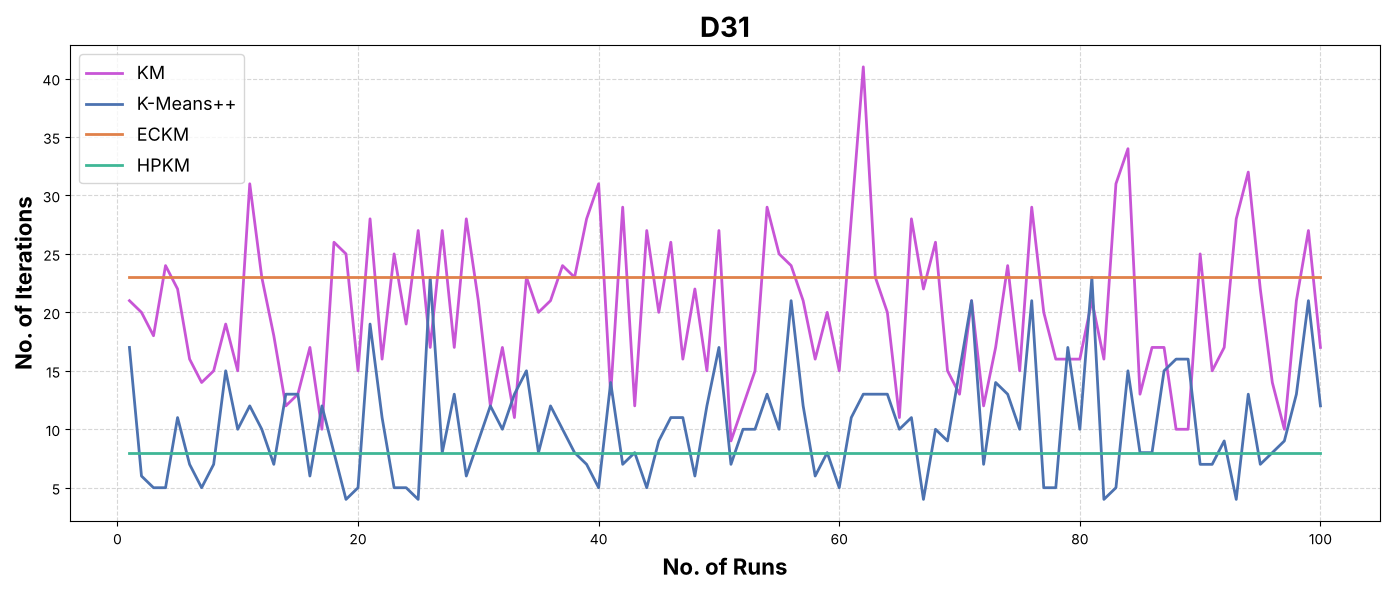

{'KM': (9, 41, 20.1), 'K-Means++': (4, 23, 10.3), 'ECKM': (23, 23, 23.0), 'HPKM': (8, 8, 8.0)}


In [8]:
X, y, k, _ = DATA[CONV_DATASET]
conv = {"KM":        [kmeans_iterative(X, k, km_random_init(X, k, s))[2] for s in range(CONV_RUNS)],
        "K-Means++": [kmeans_iterative(X, k, kmeanspp_init(X, k, s))[2] for s in range(CONV_RUNS)],
        "ECKM":      [kmeans_iterative(X, k, eckm_init(X, k))[2]] * CONV_RUNS,
        "HPKM":      [kmeans_iterative(X, k, hpkm_init(X, k))[2]] * CONV_RUNS}
pd.DataFrame(conv).to_csv(OUT_DIR + "Tables/convergence_" + CONV_DATASET + ".csv", index_label="run")
COLORS = {"KM": "#c855d6", "K-Means++": "#4c72b0", "ECKM": "#e0814a", "HPKM": "#3fb796", "Var-Part": "#8c8c8c"}
fig, ax = plt.subplots(figsize=(14, 6))
for m, v in conv.items():
    ax.plot(range(1, CONV_RUNS + 1), v, lw=2, color=COLORS[m], label=m)
ax.set_xlabel("No. of Runs", fontsize=16, fontweight="bold"); ax.set_ylabel("No. of Iterations", fontsize=16, fontweight="bold")
ax.set_title(CONV_DATASET, fontsize=20, fontweight="bold"); ax.grid(ls="--", alpha=0.5); ax.legend(fontsize=13)
plt.tight_layout(); plt.savefig(OUT_DIR + "Iterations/iterations_" + CONV_DATASET + ".png", dpi=300); plt.show()
print({m: (min(v), max(v), round(float(np.mean(v)), 1)) for m, v in conv.items()})

## 6. Per-dataset figures (clustering plots and metric bar charts)

In [9]:
def cluster_figure(name):
    X, y, k, _ = DATA[name]
    fig, axs = plt.subplots(3, 2, figsize=(15, 18)); axs = axs.flatten()
    panels = [("dataset", f"{name} Dataset"), ("true", "True Clustering"), ("KM", "KM"),
              ("ECKM", "ECKM"), ("init", "Initial Centroids of HPKM"), ("HPKM", "HPKM")]
    for ax, (kind, title) in zip(axs, panels):
        if kind == "dataset":
            ax.scatter(X[:, 0], X[:, 1], c="black", alpha=0.6)
        elif kind == "true":
            ax.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=40, alpha=0.8)
        elif kind == "init":
            init = RUNS[(name, "HPKM")][2]
            ax.scatter(X[:, 0], X[:, 1], c="black", alpha=0.6)
            ax.scatter(init[:, 0], init[:, 1], marker="X", s=200, color="red", label="Initial Centroids"); ax.legend()
        else:
            labels, cents, _ = RUNS[(name, kind)]
            ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=40, alpha=0.8)
            ax.scatter(cents[:, 0], cents[:, 1], marker="X", s=200, color="red", label="Final Centroids"); ax.legend()
        ax.set_title(title, fontsize=16, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(pad=3.0)
    plt.savefig(OUT_DIR + f"Plots/{name}_plots.png", dpi=300, bbox_inches="tight"); plt.close(fig)

def metrics_figure(name, methods=("KM", "K-Means++", "ECKM", "HPKM")):
    keys = [("SH", "SH (↑)"), ("DBI", "DB (↓)"), ("ARI", "ARI (↑)"), ("HM", "HM (↑)"),
            ("ED", "ED (↓)"), ("Time (s)", "Time (↓)")]
    fig, axs = plt.subplots(1, len(keys), figsize=(20, 5.5), sharey=False)
    for ax, (c, lab) in zip(axs, keys):
        vals = [T3.loc[(name, m), c] for m in methods]
        best = round((max if HIGH[c] else min)(vals), 2)
        bars = ax.bar(range(len(methods)), vals, color=[COLORS[m] for m in methods])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}", ha="center", va="bottom",
                    fontsize=11, fontweight="bold" if round(v, 2) == best else "normal")
        ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(lab, fontsize=14)
        for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    plt.tight_layout(rect=(0, 0.22, 1, 1))
    fig.legend(bars, methods, loc="upper center", ncol=len(methods), fontsize=13, frameon=False, bbox_to_anchor=(0.5, 0.19))
    fig.text(0.5, 0.02, name, ha="center", fontsize=24, fontweight="bold")
    plt.savefig(OUT_DIR + f"Metrics_plots/metrics_{name}.png", dpi=300, bbox_inches="tight"); plt.close(fig)

for name in FIG_DATASETS:
    cluster_figure(name); metrics_figure(name)
print("Figures saved in", OUT_DIR + "Plots/ and", OUT_DIR + "Metrics_plots/")

Figures saved in Results/Plots/ and Results/Metrics_plots/


## 7. Supplementary Material: Var-Part and the variability of KM and k-means++

In [10]:
METHODS_S = ["KM", "K-Means++", "ECKM", "Var-Part", "HPKM"]
srows = []
for name in DATASETS:
    X, y, k, _ = DATA[name]
    for m in ["KM", "K-Means++"]:
        for s in range(N_RUNS):
            res, *_ = run(m, X, y, k, s, repeats=1)
            srows.append({"Dataset": name, "Method": m, "Seed": s, **res})
    for m in ["ECKM", "Var-Part", "HPKM"]:
        res, *_ = run(m, X, y, k, 0, repeats=TIME_REPEATS)
        srows.append({"Dataset": name, "Method": m, "Seed": -1, **res})
S = pd.DataFrame(srows); S["Time (ms)"] = 1000 * S["Time (s)"]
S.to_csv(OUT_DIR + "Tables/supplementary_raw_runs.csv", index=False)
SMET = ["SH", "DBI", "ARI", "HM", "CM", "VM", "ED", "Time (ms)", "Iteration"]
SHIGH = {**HIGH, "Time (ms)": False}
SMEAN = S.groupby(["Dataset", "Method"])[SMET].mean()
SSTD  = S.groupby(["Dataset", "Method"])[SMET].std()
summary = SMEAN.round(3).astype(str) + " ± " + SSTD.round(3).fillna(0).astype(str)
summary.loc[[(d, m) for d in DATASETS for m in METHODS_S]]

SH            DBI            ARI  \
Dataset     Method                                                   
S1          KM         0.606 ± 0.041  0.619 ± 0.103  0.838 ± 0.055   
            K-Means++  0.705 ± 0.019  0.382 ± 0.046  0.978 ± 0.026   
            ECKM         0.614 ± 0.0    0.588 ± 0.0    0.833 ± 0.0   
            Var-Part     0.711 ± 0.0    0.367 ± 0.0    0.987 ± 0.0   
            HPKM         0.711 ± 0.0    0.366 ± 0.0    0.986 ± 0.0   
Aggregation KM         0.472 ± 0.013  0.742 ± 0.024  0.726 ± 0.045   
            K-Means++  0.478 ± 0.011  0.734 ± 0.021  0.745 ± 0.033   
            ECKM         0.478 ± 0.0    0.727 ± 0.0    0.745 ± 0.0   
            Var-Part     0.481 ± 0.0    0.731 ± 0.0    0.762 ± 0.0   
            HPKM         0.481 ± 0.0    0.733 ± 0.0     0.76 ± 0.0   
D31         KM         0.505 ± 0.017  0.706 ± 0.042  0.798 ± 0.039   
            K-Means++   0.56 ± 0.012  0.585 ± 0.031  0.919 ± 0.026   
            ECKM         0.482 ± 0.0    0.734 ± 0.0     0.73 ± 0.0   
            Var-Part     0.576 ± 0.0    0.547 ± 0.0    0.954 ± 0.0   
            HPKM         0.576 ± 0.0    0.547 ± 0.0    0.954 ± 0.0   
Flame       KM         0.377 ± 0.002   1.12 ± 0.004  0.454 ± 0.017   
            K-Means++  0.377 ± 0.002  1.121 ± 0.004  0.456 ± 0.021   
            ECKM         0.378 ± 0.0    1.115 ± 0.0    0.453 ± 0.0   
            Var-Part     0.371 ± 0.0    1.118 ± 0.0    0.465 ± 0.0   
            HPKM         0.378 ± 0.0    1.121 ± 0.0    0.431 ± 0.0   
Hepta       KM         0.568 ± 0.057  0.642 ± 0.105  0.836 ± 0.111   
            K-Means++  0.614 ± 0.038  0.549 ± 0.065  0.927 ± 0.071   
            ECKM         0.536 ± 0.0    0.702 ± 0.0    0.783 ± 0.0   
            Var-Part      0.63 ± 0.0    0.523 ± 0.0    0.957 ± 0.0   
            HPKM          0.63 ± 0.0    0.523 ± 0.0    0.957 ± 0.0   
R15         KM         0.598 ± 0.061  0.624 ± 0.114  0.769 ± 0.101   
            K-Means++  0.733 ± 0.033  0.359 ± 0.075  0.965 ± 0.046   
            ECKM         0.539 ± 0.0    0.771 ± 0.0    0.707 ± 0.0   
            Var-Part     0.542 ± 0.0    0.729 ± 0.0    0.712 ± 0.0   
            HPKM         0.671 ± 0.0    0.515 ± 0.0    0.904 ± 0.0   
Target      KM          0.524 ± 0.09   0.678 ± 0.09  0.571 ± 0.114   
            K-Means++  0.551 ± 0.072  0.655 ± 0.072  0.603 ± 0.087   
            ECKM         0.477 ± 0.0    0.625 ± 0.0    0.437 ± 0.0   
            Var-Part     0.378 ± 0.0     0.82 ± 0.0    0.384 ± 0.0   
            HPKM         0.563 ± 0.0    0.672 ± 0.0    0.635 ± 0.0   
Iris        KM          0.59 ± 0.017  0.614 ± 0.112  0.667 ± 0.112   
            K-Means++    0.598 ± 0.0    0.565 ± 0.0    0.716 ± 0.0   
            ECKM         0.598 ± 0.0    0.565 ± 0.0    0.716 ± 0.0   
            Var-Part     0.598 ± 0.0    0.565 ± 0.0    0.716 ± 0.0   
            HPKM         0.598 ± 0.0    0.565 ± 0.0    0.716 ± 0.0   
Breast      KM         0.424 ± 0.024  0.777 ± 0.042    0.1 ± 0.041   
            K-Means++  0.499 ± 0.074  0.834 ± 0.039  0.225 ± 0.072   
            ECKM         0.642 ± 0.0    0.807 ± 0.0    0.344 ± 0.0   
            Var-Part     0.485 ± 0.0     0.78 ± 0.0    0.175 ± 0.0   
            HPKM         0.419 ± 0.0    0.723 ± 0.0    0.104 ± 0.0   
Yeast       KM         0.343 ± 0.013  0.876 ± 0.038  0.074 ± 0.004   
            K-Means++  0.349 ± 0.009  0.863 ± 0.028  0.075 ± 0.004   
            ECKM         0.351 ± 0.0     0.79 ± 0.0    0.081 ± 0.0   
            Var-Part     0.348 ± 0.0     0.86 ± 0.0    0.069 ± 0.0   
            HPKM         0.357 ± 0.0    0.837 ± 0.0    0.072 ± 0.0   
Wine        KM         0.569 ± 0.005  0.537 ± 0.007  0.367 ± 0.008   
            K-Means++  0.567 ± 0.008  0.539 ± 0.008  0.363 ± 0.012   
            ECKM          0.56 ± 0.0    0.549 ± 0.0    0.352 ± 0.0   
            Var-Part      0.56 ± 0.0    0.549 ± 0.0    0.352 ± 0.0   
            HPKM         0.572 ± 0.0    0.533 ± 0.0    0.371 ± 0.0   

                                  HM       

In [11]:
RAND = {"KM", "K-Means++"}
def sdisp(d, m, c):
    v = SMEAN.loc[(d, m), c]
    if c == "Iteration":
        return q(v, "0.1") if m in RAND else Decimal(int(round(v)))
    return q(v)

def scell(d, m, c):
    v, s = SMEAN.loc[(d, m), c], SSTD.loc[(d, m), c]
    if m in RAND:
        p = "0.1" if c == "Iteration" else "0.01"
        return f"{q(v, p)}$\\pm${q(s, p)}"
    return f"{int(round(v))}" if c == "Iteration" else f"{q(v)}"

def sblock(d):
    out = []
    for i, m in enumerate(METHODS_S):
        cells = []
        for c in SMET:
            t = scell(d, m, c)
            if m == "HPKM":
                h = sdisp(d, m, c); others = [sdisp(d, o, c) for o in METHODS_S if o != "HPKM"]
                if (h > max(others)) if SHIGH[c] else (h < min(others)): t = f"\\textbf{{{t}}}"
            cells.append(t)
        label = "\\textbf{HPKM}" if m == "HPKM" else m
        out.append(f"{d if i == 0 else ''} & {label} & " + " & ".join(cells) + r" \\")
    out.append("& Imp.\\ over Var-Part (\\%) & " + " & ".join(
        fmt_imp(improvement(SMEAN.loc[(d, 'HPKM'), c], SMEAN.loc[(d, 'Var-Part'), c], SHIGH[c])) for c in SMET) + r" \\")
    return "\n".join(out)

snote = (r"KM and k-means++ are reported as mean$\pm$standard deviation over 30 runs (seeds 0 to 29); ECKM, Var-Part and HPKM are deterministic and are run once. "
         r"Time (ms) is the end-to-end time (initialisation and k-means iterations). Bold values in the HPKM rows mark the metrics on which HPKM is better than all the other methods. "
         r"Improvement (\%) is computed as in Table 3 of the main manuscript with Var-Part as the baseline, so a positive (bold) value means that HPKM is better than Var-Part.")
def stable(names, cap, lab):
    return "\n".join([r"\begin{table}[p]", r"\centering", f"\\caption{{{cap} {snote}}}", f"\\label{{{lab}}}", r"\scriptsize",
        r"\setlength{\tabcolsep}{3pt}", r"\begin{adjustbox}{max width=\textwidth, max totalheight=0.85\textheight}",
        r"\begin{tabular}{|c|l|ccccccccc|}", r"\hline",
        r"Dataset & Method & SH & DBI & ARI & HM & CM & VM & ED & Time (ms) & Iteration \\", r"\hline",
        "\n\\hline\n".join(sblock(d) for d in names), r"\hline", r"\end{tabular}", r"\end{adjustbox}", r"\end{table}"])

WTL = {}
for b in ["KM", "K-Means++", "ECKM", "Var-Part"]:
    WTL[b] = {}
    for c in SMET:
        w = t = l = 0
        for d in DATASETS:
            h, o = sdisp(d, "HPKM", c), sdisp(d, b, c)
            if h == o: t += 1
            elif (h > o) == SHIGH[c]: w += 1
            else: l += 1
        WTL[b][c] = f"{w}/{t}/{l}"
WTL = pd.DataFrame(WTL).T
wtl_tex = "\n".join([r"\begin{table}[htbp]", r"\centering",
    r"\caption{Number of datasets (out of 11) on which HPKM is better (W), equal (T) or worse (L) than each baseline, written as W/T/L. Values are compared after rounding to the precision shown in Tables~\ref{tab:S1} and~\ref{tab:S2}; for KM and k-means++ the mean over 30 runs is used.}",
    r"\label{tab:S3}", r"\small", r"\begin{tabular}{|l|ccccccccc|}", r"\hline",
    r"HPKM vs. & SH & DBI & ARI & HM & CM & VM & ED & Time & Iteration \\", r"\hline",
    "\n".join(f"{b} & " + " & ".join(WTL.loc[b, c] for c in SMET) + r" \\" for b in WTL.index),
    r"\hline", r"\end{tabular}", r"\end{table}"])
with open(OUT_DIR + "Tables/supplementary_tables.tex", "w") as f:
    f.write(stable(SYNTHETIC, "Comparison of KM, k-means++, ECKM, Var-Part and HPKM on the synthetic datasets.", "tab:S1") + "\n\n"
            + stable(REAL, "Comparison of KM, k-means++, ECKM, Var-Part and HPKM on the real datasets.", "tab:S2") + "\n\n" + wtl_tex + "\n")
WTL

,SH,DBI,ARI,HM,CM,VM,ED,Time (ms),Iteration
KM,8/3/0,10/1/0,7/3/1,8/2/1,7/3/1,8/2/1,8/3/0,8/0/3,9/0/2
K-Means++,4/5/2,6/3/2,6/1/4,5/4/2,5/3/3,5/3/3,6/2/3,8/0/3,6/0/5
ECKM,7/3/1,6/3/2,7/1/3,8/3/0,6/1/4,7/2/2,8/3/0,11/0/0,8/1/2
Var-Part,5/5/1,5/6/0,3/6/2,3/7/1,2/6/3,4/5/2,4/6/1,8/0/3,3/4/4


All tables (`.xlsx`, `.csv`, `.tex`) and figures are now in the `Results/` folder.